In [12]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/riyadhdata262/loan-dataset/loan_data.csv


In [13]:
!pip install -q shap

In [14]:
# Data manipulation and calculations
import pandas as pd
import tensorflow as tf
import shap

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning & Preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.ensemble import RandomForestClassifier

# Kaggle dataset path
df = pd.read_csv("/kaggle/input/datasets/riyadhdata262/loan-dataset/loan_data.csv")

# Display the first 5 rows
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [15]:
print(df.shape)
print(df.info())

(45000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaul

In [16]:
# Create a LabelEncoder object
le = LabelEncoder()

df["person_gender"] = le.fit_transform(df["person_gender"])
df["person_education"] = le.fit_transform(df["person_education"])
df["person_home_ownership"] = le.fit_transform(df["person_home_ownership"])
df["loan_intent"] = le.fit_transform(df["loan_intent"])
df["previous_loan_defaults_on_file"] = le.fit_transform(df["previous_loan_defaults_on_file"])
print(df["person_gender"].unique())
print(df["person_education"].unique())
print(df["person_home_ownership"].unique())
print(df["loan_intent"].unique())
print(df["previous_loan_defaults_on_file"].unique())


# Display the encoded dataset
print(df.head())

[0 1]
[4 3 1 0 2]
[3 2 0 1]
[4 1 3 5 2 0]
[0 1]
   person_age  person_gender  person_education  person_income  person_emp_exp  \
0        22.0              0                 4        71948.0               0   
1        21.0              0                 3        12282.0               0   
2        25.0              0                 3        12438.0               3   
3        23.0              0                 1        79753.0               0   
4        24.0              1                 4        66135.0               1   

   person_home_ownership  loan_amnt  loan_intent  loan_int_rate  \
0                      3    35000.0            4          16.02   
1                      2     1000.0            1          11.14   
2                      0     5500.0            3          12.87   
3                      3    35000.0            3          15.23   
4                      3    35000.0            3          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_sco

In [17]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)
print("\nTotal Missing values in this Dataset",missing_values.sum())

Missing values in each column:
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

Total Missing values in this Dataset 0


In [18]:
# Split features and target

X = df.drop("loan_status", axis=1)  # All columns except the target
y = df["loan_status"]               # Target column

# Check the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display the first few rows
print("\nFeatures (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features shape: (45000, 13)
Target shape: (45000,)

Features (X):
   person_age  person_gender  person_education  person_income  person_emp_exp  \
0        22.0              0                 4        71948.0               0   
1        21.0              0                 3        12282.0               0   
2        25.0              0                 3        12438.0               3   
3        23.0              0                 1        79753.0               0   
4        24.0              1                 4        66135.0               1   

   person_home_ownership  loan_amnt  loan_intent  loan_int_rate  \
0                      3    35000.0            4          16.02   
1                      2     1000.0            1          11.14   
2                      0     5500.0            3          12.87   
3                      3    35000.0            3          15.23   
4                      3    35000.0            3          14.27   

   loan_percent_income  cb_person_cred_hist_

In [19]:
# Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Maintains the class distribution
)

# Print the shapes
print("Training feature shape:", X_train.shape)
print("Testing feature shape :", X_test.shape)
print("Training target shape :", y_train.shape)
print("Testing target shape  :", y_test.shape)

Training feature shape: (36000, 13)
Testing feature shape : (9000, 13)
Training target shape : (36000,)
Testing target shape  : (9000,)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-09-04 13:38:33.116695: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8645 - loss: 0.2887 - val_accuracy: 0.8863 - val_loss: 0.2381
Epoch 2/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8931 - loss: 0.2330 - val_accuracy: 0.8922 - val_loss: 0.2280
Epoch 3/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8970 - loss: 0.2232 - val_accuracy: 0.8983 - val_loss: 0.2202
Epoch 4/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9007 - loss: 0.2174 - val_accuracy: 0.8988 - val_loss: 0.2181
Epoch 5/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9013 - loss: 0.2150 - val_accuracy: 0.9004 - val_loss: 0.2139
Epoch 6/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9044 - loss: 0.2124 - val_accuracy: 0.8997 - val_loss: 0.2138
Epoch 7/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9051 - loss: 0.2076 - val_accuracy: 0.9000 - val_loss: 0.2119
Epoch 8/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9067 - loss: 0.2077 - val_accu

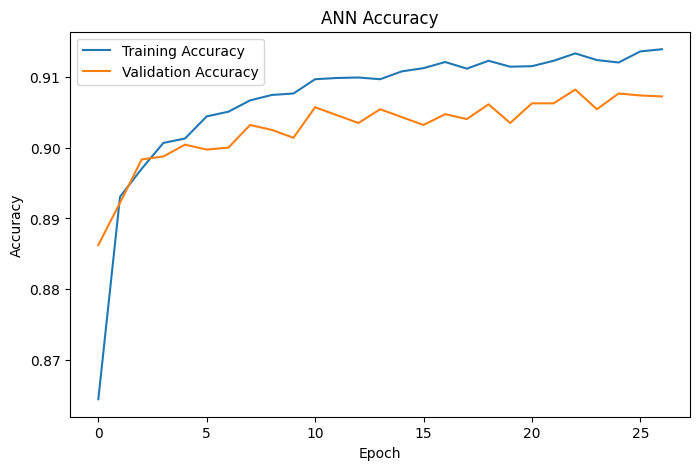

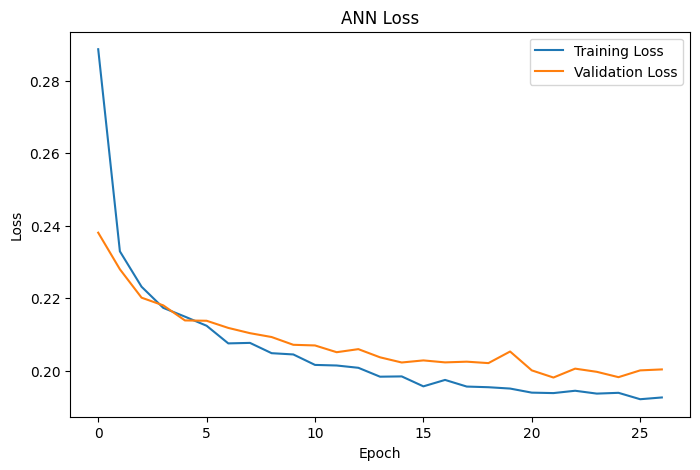

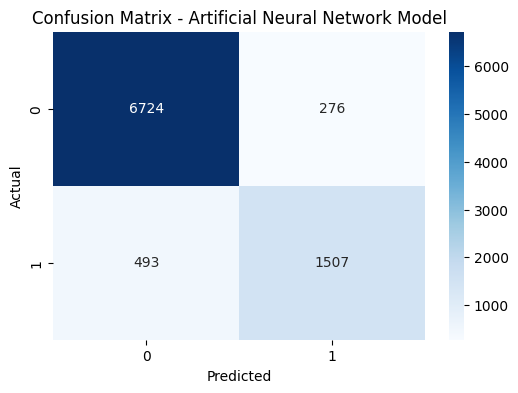

In [20]:
# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Build the Artificial Neural Network
ann_model = Sequential()

# Input Layer + Hidden Layer 1
ann_model.add(Dense(units=64,
              activation='relu',
              input_dim=X_train_scaled.shape[1]))

ann_model.add(Dropout(0.3))

# Hidden Layer 2
ann_model.add(Dense(units=32,
              activation='relu'))

ann_model.add(Dropout(0.2))

# Hidden Layer 3
ann_model.add(Dense(units=16,
              activation='relu'))

# Output Layer (Binary Classification)
ann_model.add(Dense(units=1,
              activation='sigmoid'))

# Display the model architecture
ann_model.summary()

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Evaluate the model
loss, ann_accuracy = ann_model.evaluate(X_test_scaled, y_test, verbose=0)

print(f"Test Loss     : {loss:.4f}")
print(f"Test Accuracy : {ann_accuracy:.4f}")

# Predict probabilities
y_prob = ann_model.predict(X_test_scaled)

# Convert probabilities into binary classes
y_pred = (y_prob >= 0.5).astype(int)

print(y_pred[:10])

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Accuracy Plot
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('ANN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss Plot
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('ANN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plot confusion matrix
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Artificial Neural Network Model')
plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8650 - loss: 0.2870 - val_accuracy: 0.8867 - val_loss: 0.2362
Epoch 2/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8929 - loss: 0.2327 - val_accuracy: 0.8935 - val_loss: 0.2267
Epoch 3/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8968 - loss: 0.2249 - val_accuracy: 0.8969 - val_loss: 0.2219
Epoch 4/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8983 - loss: 0.2184 - val_accuracy: 0.8967 - val_loss: 0.2176
Epoch 5/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9015 - loss: 0.2147 - val_accuracy: 0.8992 - val_loss: 0.2166
Epoch 6/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9030 - loss: 0.2128 - val_accuracy: 0.9008 - val_loss: 0.2129
Epoch 7/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9042 - loss: 0.2096 - val_accuracy: 0.9028 - val_loss: 0.2113
Epoch 8/100
900/900 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9029 - loss: 0.2086 - val_accu

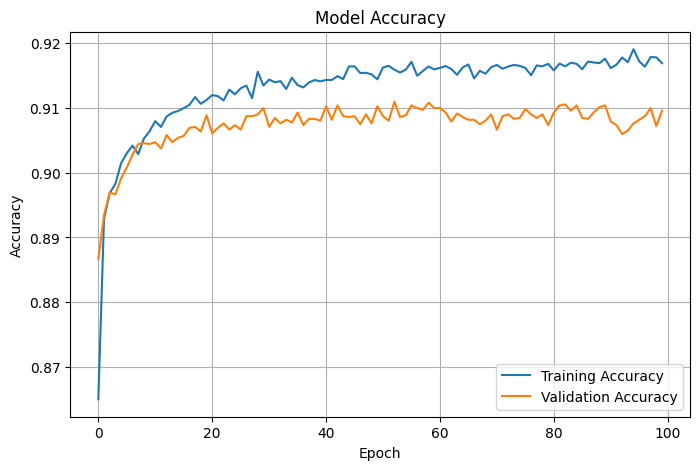

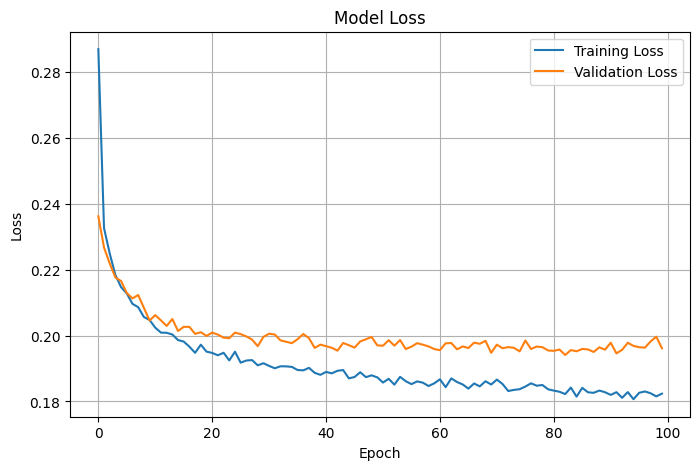

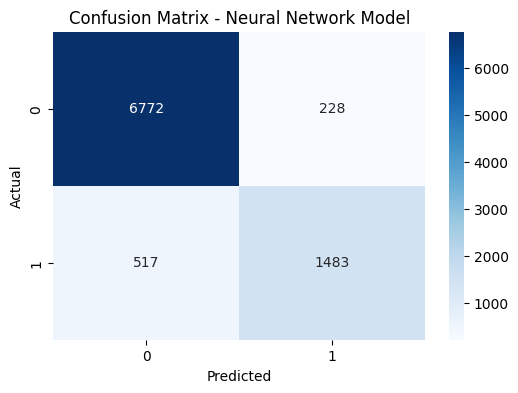

In [21]:
# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Build the model
nn_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')  # Binary classification
])

# Compile the model
nn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model summary
nn_model.summary()

history = nn_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

test_loss, test_accuracy = nn_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Predict probabilities
y_prob = nn_model.predict(X_test_scaled)

# Convert probabilities to class labels
y_pred = (y_prob > 0.5).astype(int)

print("First 10 Predictions:")
print(y_pred[:10].flatten())


nn_accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {nn_accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)


# Accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot confusion matrix
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Neural Network Model')
plt.show()

Test Accuracy: 0.9279
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      7000
           1       0.89      0.77      0.83      2000

    accuracy                           0.93      9000
   macro avg       0.91      0.87      0.89      9000
weighted avg       0.93      0.93      0.93      9000

Confusion Matrix:
[[6807  193]
 [ 456 1544]]
                           Feature  Importance
12  previous_loan_defaults_on_file    0.225186
9              loan_percent_income    0.162817
8                    loan_int_rate    0.161792
3                    person_income    0.125939
5            person_home_ownership    0.065828
6                        loan_amnt    0.059481
11                    credit_score    0.056721
7                      loan_intent    0.035554
0                       person_age    0.029747
4                   person_emp_exp    0.027217
10      cb_person_cred_hist_length    0.025061
2                 p

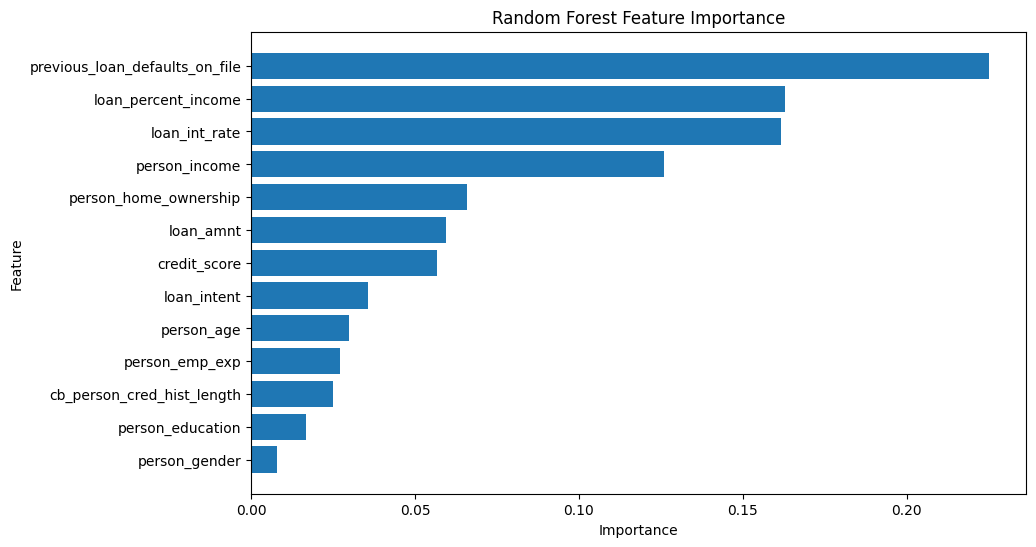

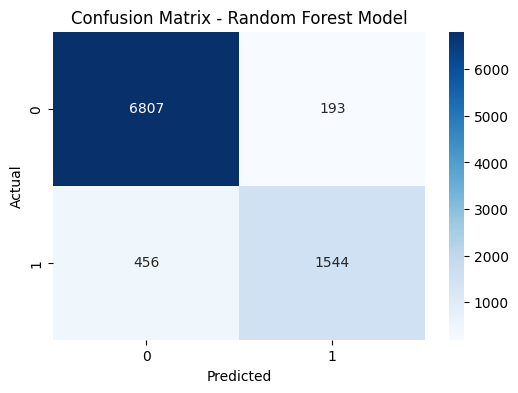

In [22]:
# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=1000,
    criterion='gini',
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Predict probabilities (optional)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {rf_accuracy:.4f}")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10,6))
plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.show()

# Plot confusion matrix
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest Model')
plt.show()

SHAP version: 0.51.0
SHAP dataset shape: (300, 13)
Calculating SHAP values...
SHAP calculation completed.

===== SHAP FEATURE IMPORTANCE =====
                           Feature  SHAP Importance
0   previous_loan_defaults_on_file         0.169158
1                    loan_int_rate         0.071321
2              loan_percent_income         0.066316
3            person_home_ownership         0.045279
4                    person_income         0.040121
5                      loan_intent         0.019796
6                     credit_score         0.017305
7                        loan_amnt         0.011675
8                       person_age         0.002856
9       cb_person_cred_hist_length         0.002649
10                  person_emp_exp         0.002635
11                person_education         0.001800
12                   person_gender         0.001076


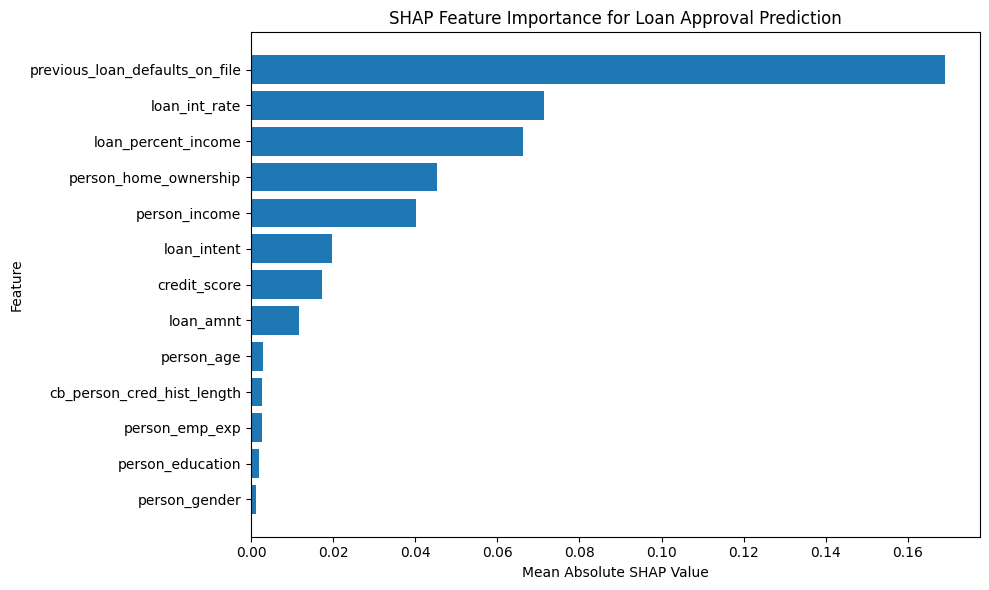

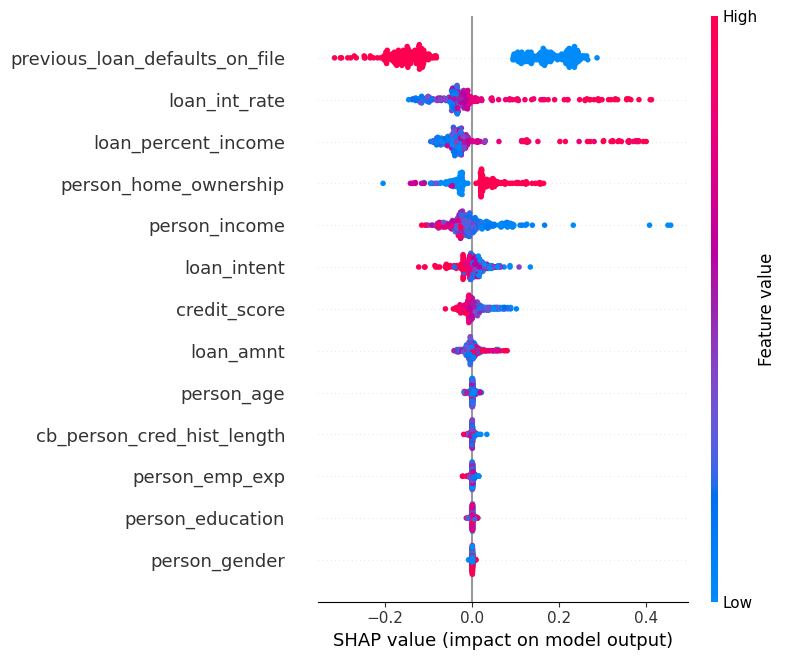

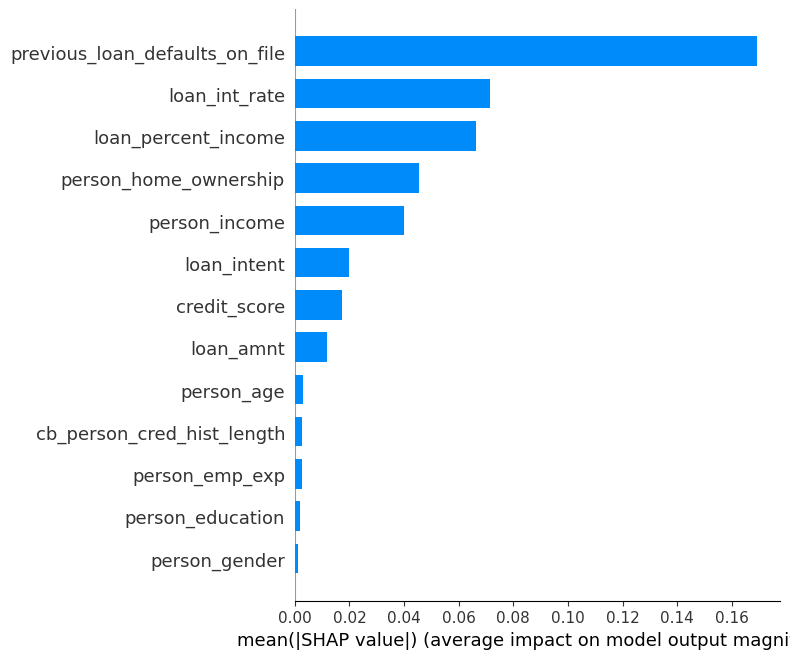

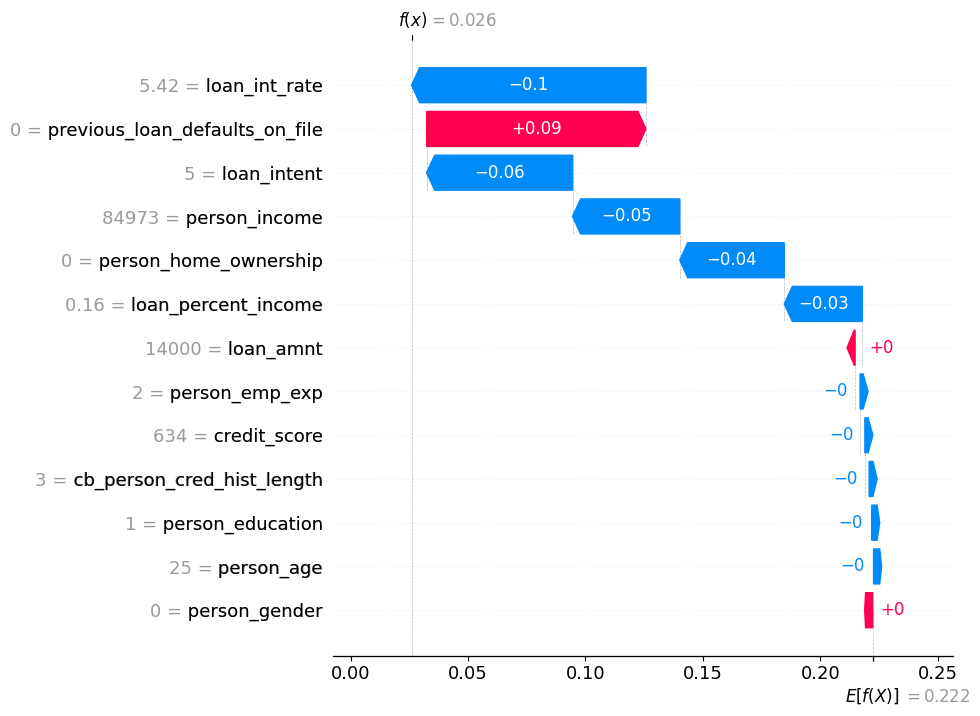


SHAP analysis completed successfully


In [23]:
# ============================================================
# EXPLAINABLE AI (XAI) USING SHAP
# Random Forest - Loan Approval Prediction
# ============================================================

!pip install -q shap

import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

# ============================================================
# 1. Select samples for SHAP
# ============================================================

# Start small to test
X_shap = X_test.iloc[:300].copy()

print("SHAP dataset shape:", X_shap.shape)


# ============================================================
# 2. Create Tree Explainer
# ============================================================

explainer = shap.TreeExplainer(rf_model)


# ============================================================
# 3. Calculate SHAP values
# ============================================================

print("Calculating SHAP values...")

shap_result = explainer(X_shap)

print("SHAP calculation completed.")


# ============================================================
# 4. Handle Binary Classification
# ============================================================

# New SHAP versions may return:
# samples × features × classes

if len(shap_result.values.shape) == 3:

    shap_values_approved = shap_result.values[:, :, 1]

    base_value = explainer.expected_value[1]

else:

    shap_values_approved = shap_result.values

    base_value = explainer.expected_value


# ============================================================
# 5. Global Feature Importance
# ============================================================

shap_importance = pd.DataFrame({

    "Feature": X_shap.columns,

    "SHAP Importance":
        np.abs(shap_values_approved).mean(axis=0)

})

shap_importance = shap_importance.sort_values(
    by="SHAP Importance",
    ascending=False
).reset_index(drop=True)


print("\n===== SHAP FEATURE IMPORTANCE =====")
print(shap_importance)


# ============================================================
# 6. Feature Importance Plot
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    shap_importance["Feature"],
    shap_importance["SHAP Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")

plt.title(
    "SHAP Feature Importance for Loan Approval Prediction"
)

plt.tight_layout()

plt.show()


# ============================================================
# 7. SHAP Beeswarm Plot
# ============================================================

shap.summary_plot(
    shap_values_approved,
    X_shap,
    show=True
)


# ============================================================
# 8. SHAP Bar Plot
# ============================================================

shap.summary_plot(
    shap_values_approved,
    X_shap,
    plot_type="bar",
    show=True
)


# ============================================================
# 9. Local Explanation
# ============================================================

sample_index = 0

local_explanation = shap.Explanation(

    values=shap_values_approved[sample_index],

    base_values=base_value,

    data=X_shap.iloc[sample_index].values,

    feature_names=X_shap.columns.tolist()

)


# ============================================================
# 10. Waterfall Plot
# ============================================================

shap.plots.waterfall(
    local_explanation,
    max_display=13
)


# ============================================================
# 11. Save Results
# ============================================================

shap_importance.to_csv(
    "SHAP_Feature_Importance.csv",
    index=False
)

print("\n===================================")
print("SHAP analysis completed successfully")
print("===================================")

/tmp/ipykernel_58/1770644792.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Model', data=results_df, palette='magma')


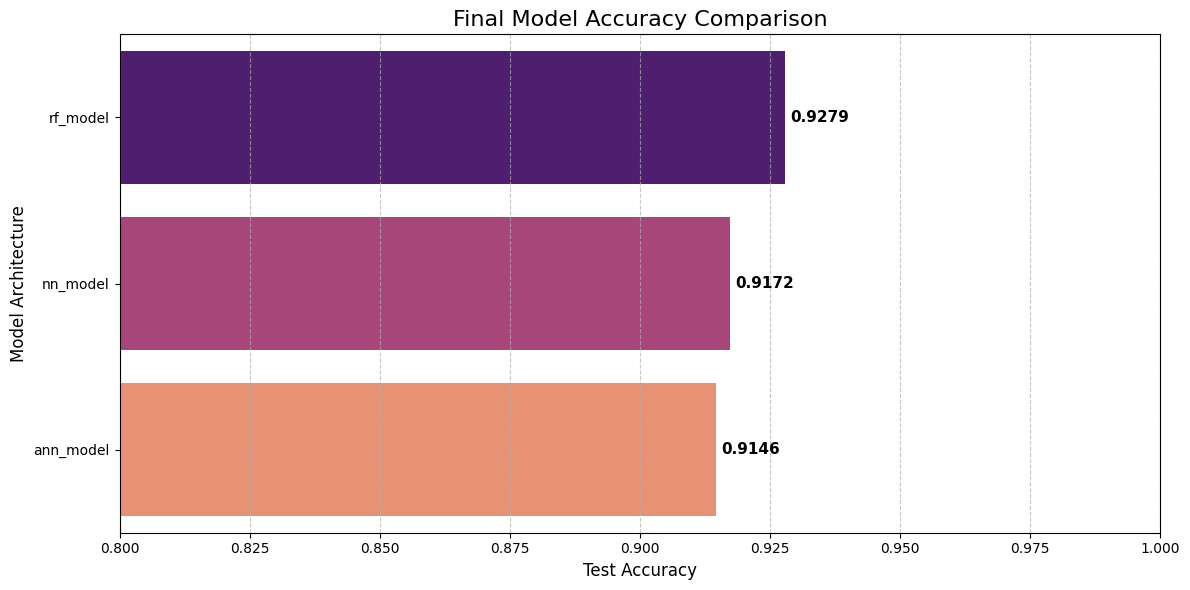

In [24]:
# Collect all accuracies into a DataFrame
results_df = pd.DataFrame({
    'Model': [
        'nn_model',
        'ann_model',
        'rf_model'
    ],
    'Accuracy': [
        nn_accuracy,
        ann_accuracy,
        rf_accuracy
    ]
})

results_df = results_df.sort_values(by='Accuracy', ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x='Accuracy', y='Model', data=results_df, palette='magma')

# Add accuracy labels to the bars
for index, value in enumerate(results_df['Accuracy']):
    plt.text(value + 0.001, index, f'{value:.4f}', va='center', fontsize=11, fontweight='bold')

plt.title('Final Model Accuracy Comparison', fontsize=16)
plt.xlim(0.80, 1.0)
plt.xlabel('Test Accuracy', fontsize=12)
plt.ylabel('Model Architecture', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()